# Importation, statistiques descriptives et graphiques


In [ ]:
#modification du dossier par défaut
import os
#importation des données
import pandas
fromage = pandas.read_table("fromage.txt",sep="\t",header=0,index_col=0)
#dimension des données
print(fromage.shape)
#statistiques descriptives
print(fromage.describe())
#graphique - croisement deux à deux des variables
from pandas.plotting import scatter_matrix
scatter_matrix(fromage,figsize=(9,9))

# Classification ascendante hiérarchique
Utilisation du package « scipy »

In [ ]:
#librairies pour la CAH
from matplotlib import pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
#générer la matrice des liens
Z = linkage(fromage,method='ward',metric='euclidean')
#affichage du dendrogramme
plt.title("CAH")
dendrogram(Z,labels=fromage.index,orientation='left',color_threshold=0)
plt.show()

# Découpage en classes – Matérialisation des groupes

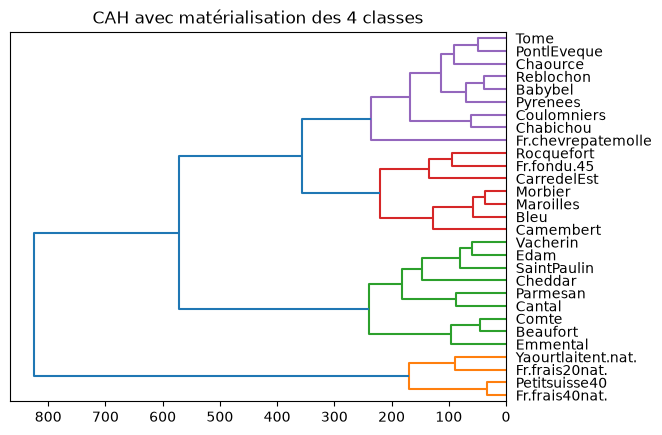

groupes_cah: [3 4 2 3 3 2 4 4 2 2 4 2 2 4 3 1 1 3 3 2 1 4 4 4 3 2 4 2 1]


,Fromages
1,Fr.frais20nat.
1,Yaourtlaitent.nat.
1,Petitsuisse40
1,Fr.frais40nat.
2,Comte
2,Beaufort
2,Cheddar
2,Cantal
2,Parmesan
2,Edam


In [6]:
from scipy.cluster.hierarchy import fcluster
#matérialisation des 4 classes (hauteur t = 7)
plt.title('CAH avec matérialisation des 4 classes')
dendrogram(Z,labels=fromage.index,orientation='left',color_threshold=300)
plt.show()
#découpage à la hauteur t = 7 ==> identifiants de 4 groupes obtenus
groupes_cah = fcluster(Z,t=300,criterion='distance')
print("groupes_cah:", groupes_cah)
#index triés des groupes
import numpy as np
idg = np.argsort(groupes_cah)
#affichage des observations et leurs groupes
display(pandas.DataFrame(fromage.index[idg],groupes_cah[idg]))

In [5]:
print(Z[:, 2])

[ 33.64119498  37.47452468  38.02841043  45.00877692  49.66356814
  58.4642911   59.83895053  61.06209954  70.17045912  80.84746955
  87.48159806  88.28833445  90.54197921  94.70348462  96.77015725
 112.88916393 127.57537641 135.11430963 147.18239252 167.84122209
 168.68274956 182.17390044 219.67433797 236.78176251 238.93372628
 356.96703351 571.05871599 825.48803759]


# Méthode des centres mobiles
Utilisation du package « scikit-learn »

In [11]:
#k-means sur les données centrées et réduites
from sklearn import cluster
kmeans = cluster.KMeans(n_clusters=4)
kmeans.fit(fromage)
#index triés des groupes
idk = np.argsort(kmeans.labels_)
#affichage des observations et leurs groupes
print(pandas.DataFrame(fromage.index[idk],kmeans.labels_[idk]))
#distances aux centres de classes des observations
print(kmeans.transform(fromage))
#correspondance avec les groupes de la CAH
pandas.crosstab(groupes_cah,kmeans.labels_)

             Fromages
0         CarredelEst
0                Bleu
0            Chaource
0           Camembert
0         Fr.fondu.45
0          Rocquefort
1             Cheddar
1            Beaufort
1            Emmental
1               Comte
1            Vacherin
1                Edam
2       Petitsuisse40
2      Fr.frais40nat.
2      Fr.frais20nat.
2  Fr.chevrepatemolle
2  Yaourtlaitent.nat.
3             Babybel
3              Cantal
3           Chabichou
3         Coulomniers
3            Parmesan
3             Morbier
3           Maroilles
3           Reblochon
3            Pyrenees
3         PontlEveque
3         SaintPaulin
3                Tome
[[ 92.39377083 298.50120835 351.97587872 168.34726324]
 [125.02943209 139.99964782 276.45921435  25.57627889]
 [278.90823859  38.57004091 331.73079628 167.77720159]
 [ 74.4654879  223.14028784 366.85365093  99.56364485]
 [ 88.45487864 234.87900727 303.79991639 112.69201854]
 [155.04557036 138.46426033 348.56259008  79.41556968]
 [178.5914

col_0,0,1,2,3
row_0,,,,
1,0,0,4,0
2,0,6,0,3
3,5,0,0,2
4,1,0,1,7


## Aide à la détection du nombre adéquat de groupes


[0.50681355 0.37931202 0.34192984 0.29853068 0.29022759 0.2613174
 0.27175259 0.25959146 0.21312796]


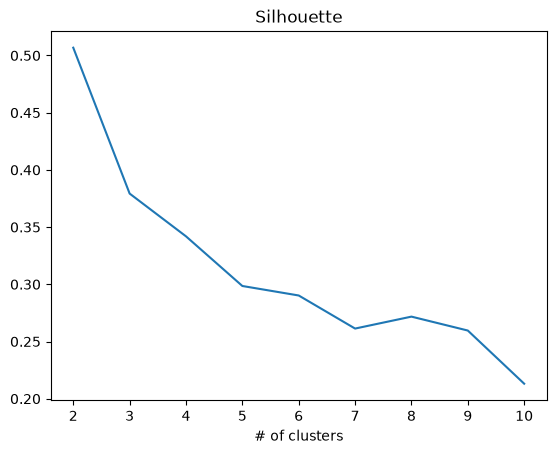

In [13]:
#librairie pour évaluation des partitions
from sklearn import metrics
#utilisation de la métrique "silhouette"
#faire varier le nombre de clusters de 2 à 10
res = np.arange(9,dtype="double")
for k in np.arange(9):
  km = cluster.KMeans(n_clusters=k+2)
  km.fit(fromage)
  res[k] = metrics.silhouette_score(fromage,km.labels_)
print(res)
#graphique
import matplotlib.pyplot as plt
plt.title("Silhouette")
plt.xlabel("# of clusters")
plt.plot(np.arange(2,11,1),res)
plt.show()

# INTERPRÉTATION DES CLASSES

In [15]:
#moyenne par variable
m = fromage.mean()
#TSS
TSS = fromage.shape[0]*fromage.var(ddof=0)
print(TSS)
#data.frame conditionnellement aux groupes
gb = fromage.groupby(kmeans.labels_)
#effectifs conditionnels
nk = gb.size()
print(nk)
#moyennes conditionnelles
mk = gb.mean()
print(mk)
#pour chaque groupe écart à la moyenne par variable
EMk = (mk-m)**2
#pondéré par les effectifs du groupe
EM = EMk.multiply(nk,axis=0)
#somme des valeurs => BSS
BSS = np.sum(EM,axis=0)
print(BSS)
#carré du rapport de corrélation
#variance expliquée par l'appartenance aux groupes
#pour chaque variable
R2 = BSS/TSS
print(R2)

calories       236550.965517
sodium         330711.034483
calcium        147292.285517
lipides          1850.550345
retinol         16347.948276
folates          3848.226897
proteines        1356.282069
cholesterol     22339.034483
magnesium        3586.965517
dtype: float64
0     6
1     6
2     5
3    12
dtype: int64
     calories      sodium     calcium    lipides    retinol    folates  \
0  312.333333  350.250000  160.500000  25.883333  78.166667  24.250000   
1  372.000000  120.666667  243.433333  30.266667  59.733333   3.166667   
2  122.600000   67.800000  121.560000   8.720000  74.220000  19.380000   
3  331.833333  244.000000  196.241667  26.675000  63.400000   9.658333   

   proteines  cholesterol  magnesium  
0  19.650000    76.666667  22.833333  
1  25.583333   103.333333  39.833333  
2   7.980000    24.600000  12.200000  
3  22.800000    80.000000  28.750000  
calories       201530.765517
sodium         280879.026149
calcium         45712.251017
lipides          1509.4381

## Analyse en composantes principales (ACP)


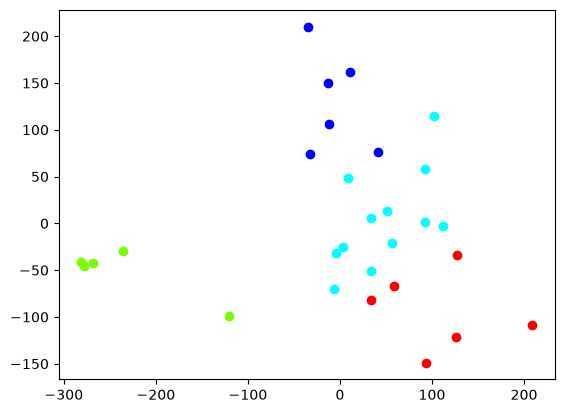

In [16]:
# ACP
from sklearn.decomposition import PCA
acp = PCA(n_components=2).fit_transform(fromage)
#projeter dans le plan factoriel
#avec un code couleur différent selon le groupe
#remarquer le rôle de zip() dans la boucle
for couleur,k in zip(['red','blue','lawngreen','aqua'],[0,1,2,3]):
  plt.scatter(acp[kmeans.labels_==k,0],acp[kmeans.labels_==k,1],c=couleur)
plt.show()

# Approfondir l’analyse
Retirer les fromages frais du jeu de données


(23, 9)


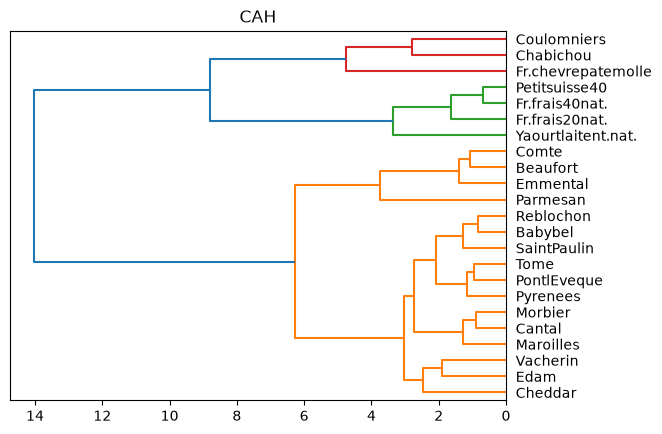

[1 1 1 3 1 1 3 1 1 3 2 2 1 1 1 2 1 1 1 1 1 1 2]


In [17]:
from sklearn import preprocessing
#retirer des observations le groupe n°0 du k-means précédent
fromage_subset = fromage.iloc[kmeans.labels_!=0,:]
print(fromage_subset.shape)
#centrer et réduire
fromage_subset_cr = preprocessing.scale(fromage_subset)
#générer la matrice des liens
Z_subset = linkage(fromage_subset_cr,method='ward',metric='euclidean')
#cah et affichage du dendrogramme
plt.title("CAH")
dendrogram(Z_subset,labels=fromage_subset.index,orientation='left',color_threshold=7)
plt.show()
#groupes
groupes_subset_cah = fcluster(Z_subset,t=7,criterion='distance')
print(groupes_subset_cah)

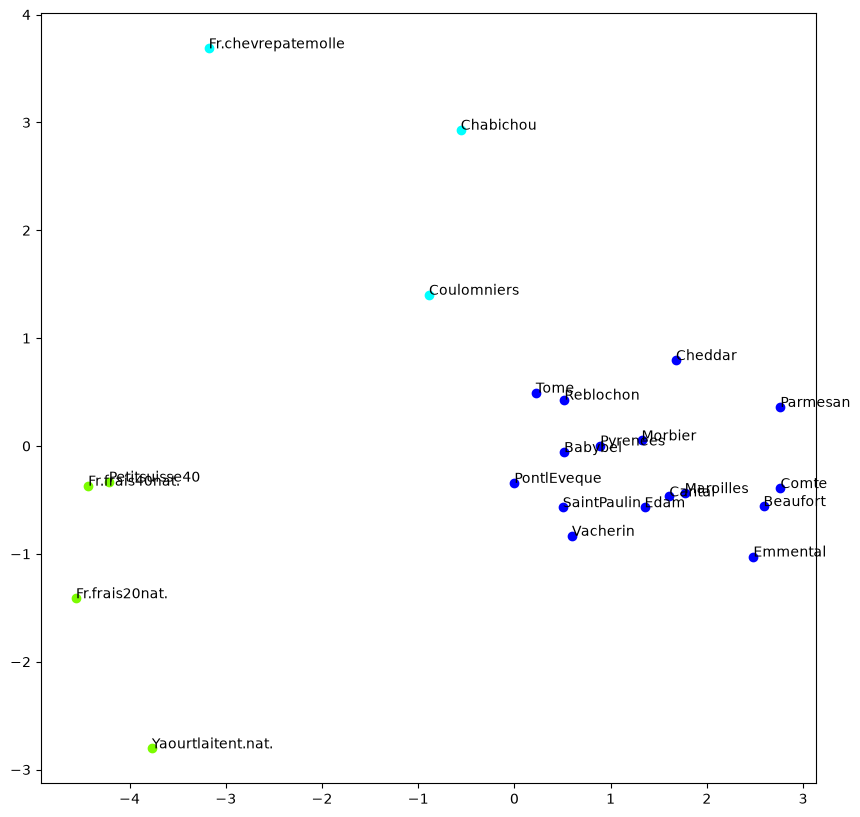

In [18]:
#ACP
acp_subset = PCA(n_components=2).fit_transform(fromage_subset_cr)
#projeter dans le plan factoriel
#avec un code couleur selon le groupe
#remarquer le rôle de zip()
plt.figure(figsize=(10,10))
for couleur,k in zip(['blue','lawngreen','aqua'],[1,2,3]):
  plt.scatter(acp_subset[groupes_subset_cah==k,0],acp_subset[groupes_subset_cah==k,1],c=couleur)
#mettre les labels des points
#remarquer le rôle de enumerate()
for i,label in enumerate(fromage_subset.index):
  plt.annotate(label,(acp_subset[i,0],acp_subset[i,1]))
plt.show()